In [33]:
import numpy as np
import matplotlib.pyplot as plt

SVD offers geometric intuitions to descibes the transformation matrix

# CONSTRUCTION OF SVD without built-in-function

In [34]:
A = np.array([[2,5],
              [3,9],
              [4,1]])
# To obtain U from eigenvector of AAT (column operation)
_, U = np.linalg.eig(A @ A.T)

# To obtain VT from eigenvector of ATA (row operation)
lam, V = np.linalg.eig(A.T @ A)
VT = V.T

# To obtain singular value E -> submatrix (diagonal matrix)
sigma = np.sqrt(lam)
E = sigma

# diagonal matrix
diag = np.diag(E)
np.round(diag)

array([[ 3.,  0.],
       [ 0., 11.]])

# CONSTRUCTION OF SVD using built-in-function

In [35]:
A = np.array([[2,3],
              [5,3],
              [4,1]])

U, E, VT = np.linalg.svd(A)

# U: u1, u2 are left singular vectors
u1 = U[:, 0]
u2 = U[:, 1]

# V: v1, v2 are right singular vectors
v1 = VT[0,: ]
v2 = VT[1, : ]

# singular value
sigma_max = np.max(E)
sigma_min = np.min(E)

# condition number
cn = sigma_max/sigma_min

# Outputs
# print(f"u1 =\n {np.column_stack([u1])}")
# print(f"\nu2 =\n {np.column_stack([u2])}")

# print(f"\nv1 =\n {np.column_stack([v1])}")
# print(f"v2 =\n {np.column_stack([v2])}")

# print(f"\nCondition number = {round(cn)}")

# Verification of A = U E VT
# Avi = sigma_ui, for each i AV = U E,  VT = V^-1 , A = U E VT

Av1 = A @ v1
Av2 = A @ v2
sigma = E
sigma_u1 = sigma[0] * u1
sigma_u2 = sigma[1] * u2

print("Verification of A = U E VT ")
print(f"Av1 = sigma_u1 -> {(np.allclose(Av1, sigma_u1))}")
print(f"Av2 = sigma_u2 -> {(np.allclose(Av2, sigma_u2))}")

print(f"Dimension of domain (U) = {U.shape}")
print(f"Dimension of codomain (VT) = {VT.shape}")


Verification of A = U E VT 
Av1 = sigma_u1 -> True
Av2 = sigma_u2 -> True
Dimension of domain (U) = (3, 3)
Dimension of codomain (VT) = (2, 2)


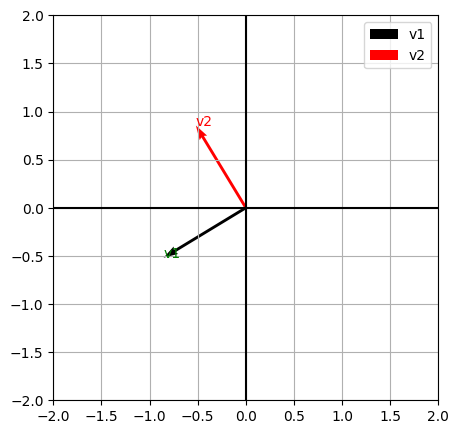

In [36]:
# origin
origin = np.eye(2)[:0]

fig, ax = plt.subplots(figsize=(5,5))

# plot
ax.quiver(*origin, *v1, angles='xy', scale_units='xy', scale=1, color='k', label='v1')
ax.quiver(*origin, *v2, angles='xy', scale_units='xy', scale=1, color='r', label='v2')

# axes 
ax.axhline(0, color='k')
ax.axvline(0, color='k')

# figure style
ax.grid()
ax.set_xlim(-2,2)
ax.set_ylim(-2,2)
ax.set_aspect('equal')
ax.legend()

# arrow representation
ax.text(*v1, s='v1', color='g')
ax.text(*v2, s='v2', color='r')


plt.show()

In [37]:
A = np.array([
    [7,2,4],
    [9,10,6],
    [5,3,9],
    [1,4,7]
])

# Matrix factorization into A = U E VT
U,E,VT  = np.linalg.svd(A)

print(f"U =\n {U}")
print(f"\n E =\n {np.diag(E)}")
print(f"\nVT =\n {VT}")
print()
print(A @ A.T)
print()
print(A.T @ A)

U =
 [[-0.37514195  0.20009821 -0.72133672  0.54671982]
 [-0.70106076  0.56893121  0.39655057 -0.16606848]
 [-0.49725249 -0.5491825  -0.33498293 -0.58217264]
 [-0.3471632  -0.57851238  0.45848383  0.57844076]]

 E =
 [[20.26862524  0.          0.        ]
 [ 0.          6.13010609  0.        ]
 [ 0.          0.          4.31330848]]

VT =
 [[-0.58064945 -0.52501349 -0.62225963]
 [ 0.52146625  0.34712474 -0.77947249]
 [-0.62523529  0.77708767 -0.07221903]]

[[ 69 107  77  43]
 [107 217 129  91]
 [ 77 129 115  80]
 [ 43  91  80  66]]

[[156 123 134]
 [123 129 123]
 [134 123 182]]


In [38]:
A = np.random.randint(0, 2, size=((10, 10)))
np.linalg.det(A)


np.float64(0.0)

In [39]:
A = np.ones((7, 7))
A[:, :2] = A[:, :2] * 1
A[:, 2:4] = A[:, 2:4] * 5
A[:, 4:] = A[:, 4:] * 50
A

array([[ 1.,  1.,  5.,  5., 50., 50., 50.],
       [ 1.,  1.,  5.,  5., 50., 50., 50.],
       [ 1.,  1.,  5.,  5., 50., 50., 50.],
       [ 1.,  1.,  5.,  5., 50., 50., 50.],
       [ 1.,  1.,  5.,  5., 50., 50., 50.],
       [ 1.,  1.,  5.,  5., 50., 50., 50.],
       [ 1.,  1.,  5.,  5., 50., 50., 50.]])

In [40]:
our_map = "Set1"
#our_map = 'gray'

In [41]:
U, S, VT = np.linalg.svd(A)
S = np.diag(S)  # diagonal elements

In [42]:
def draw_svd(A, U, S, VT, our_map):
  # Original Matrix
  plt.subplot(221)
  plt.title('Original matrix')
  plt.imshow(A, cmap =our_map)
  
  plt.axis('off')

  # U Matrix (Output Rotation)
  plt.subplot(222)
  plt.title('U  matrix')
  plt.imshow(U, cmap =our_map)
  
  plt.axis('off')

  # Diagonal Matrix
  plt.subplot(223)
  plt.title('Sigma matrix')
  plt.imshow(S, cmap =our_map)
  
  plt.axis('off')

  # V Matrix (Input Rotation)
  plt.subplot(224)
  plt.title('V matrix')
  plt.imshow(VT, cmap =our_map)
  
  plt.axis('off')

In [43]:
def truncate_u_s(S, U, VT):
    threshold = 0.001
    s = np.diag(S)
    index = s < threshold

    
    U[:, index] = 0
    VT[index, :] = 0
    return U, VT


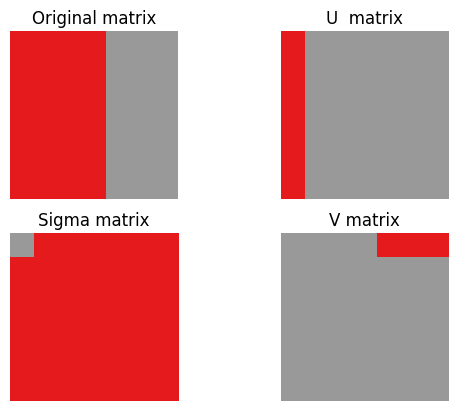

In [44]:
U, VT = truncate_u_s(S, U, VT)
draw_svd(A, U, S, VT, our_map)

In [57]:
from sklearn.datasets import fetch_olivetti_faces
face = fetch_olivetti_faces()

X = face.data
# the shape of image are 64 * 64 dimension
X


array([[0.30991736, 0.3677686 , 0.41735536, ..., 0.15289256, 0.16115703,
        0.1570248 ],
       [0.45454547, 0.47107437, 0.5123967 , ..., 0.15289256, 0.15289256,
        0.15289256],
       [0.3181818 , 0.40082645, 0.49173555, ..., 0.14049587, 0.14876033,
        0.15289256],
       ...,
       [0.5       , 0.53305787, 0.607438  , ..., 0.17768595, 0.14876033,
        0.19008264],
       [0.21487603, 0.21900827, 0.21900827, ..., 0.57438016, 0.59090906,
        0.60330576],
       [0.5165289 , 0.46280992, 0.28099173, ..., 0.35950413, 0.3553719 ,
        0.38429752]], shape=(400, 4096), dtype=float32)

In [55]:
faces = X[0, :].reshape((64, 64))

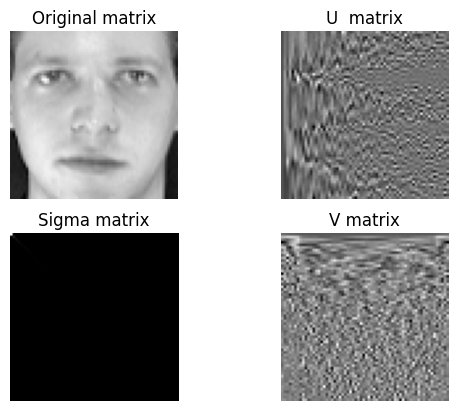

In [56]:
# we decompose the image of a face
U, S, VT = np.linalg.svd(faces)
S = np.diag(S)
faces = faces.astype('float')
draw_svd(faces, U, S, VT, 'gray')